# DRAPE pulse-level simulation

Load experimental DRAPE sweep data, pick a $\beta$ scheme, and (optionally) re-run the QuTiP pulse-level simulation.

**This is the slow notebook.** A full optimization takes ~1 hour. Most users should load the cached results instead.

In [16]:
import os, sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))   # run from the repository root; data/ and figures/ are relative to it
import numpy as np
import matplotlib.pyplot as plt
import drape_lib as dl

%matplotlib inline
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

## Load transmon couplings

In [17]:
rabi    = np.load(dl.DATA_DIR + 'measured/lambda_values.npz', allow_pickle=True)
lambdas = rabi['lambdas']
lambdas

array([0.526, 0.621, 0.753])

## Load DRAPE sweep data

In [3]:
drape_data      = np.load(dl.DATA_DIR + 'simulated/drape/0.2390/drape_sim_500pts_-2.0_1.25_0.2390_k1to11.npz')
print(drape_data)

NpzFile './data/drape/0.2390/drape_sim_500pts_-2.0_1.25_0.2390_k1to11.npz' with keys: beta_range, drape_pops, y_fit, ks


In [7]:
beta_range = drape_data['beta_range']  # physical units
drape_pops = drape_data['drape_pops']
y_fit = drape_data['y_fit']

beta_range.shape, drape_pops.shape, y_fit.shape

((500,), (11, 500, 4), (11, 500, 4))

In [ ]:
# Per-trace empirical noise standard deviations (measured from
# r[i] = y[i,:,2] - y_fit[i] on the drag_ape_data file).
EMPIRICAL_STD = np.array([0.00636, 0.00734, 0.00685, 0.00649, 0.00702, 0.00934,
                          0.00653, 0.00623, 0.00686, 0.00711, 0.00634, 0.00532,
                          0.00463, 0.00675, 0.00875, 0.00574, 0.00768, 0.00485,
                          0.00657, 0.00559, 0.00654, 0.00621, 0.00586, 0.00592])/3
print(EMPIRICAL_STD.shape)  # ≈ [0.00212, 0.00245, 0.00228, 0.00216, 0.00301, 0.00381, 0.00218, 0.00208, 0.00229]
POOLED_STD = float(np.sqrt((EMPIRICAL_STD**2).mean()))   # ≈ 0.00812

def add_noise(y_fit_i, sigma=None, i=None, rng=None):
    """
    Return y_fit_noisy[i] = y_fit[i] + Gaussian white noise.
 
    Parameters
    ----------
    y_fit_i : 1-D array, shape (N,)
        Clean fit values for one trace.
    sigma : float, optional
        Noise standard deviation. If None, use the per-trace empirical std
        when `i` is given, otherwise the pooled empirical std (~0.0081).
    i : int in {0,...,5}, optional
        Trace index used to look up the empirical std.
    rng : np.random.Generator, optional
        Pass for reproducibility (e.g. np.random.default_rng(0)).
 
    Returns
    -------
    y_fit_noisy_i : 1-D array, shape (N,)
    """
    if rng is None:
        rng = np.random.default_rng(0)   # fixed seed so the injected noise is reproducible
    if sigma is None:
        sigma = EMPIRICAL_STD[i] if i is not None else POOLED_STD
    return np.asarray(y_fit_i) + rng.normal(0.0, sigma, size=np.shape(y_fit_i))

(24,)


Text(0, 0.5, '|2⟩ population')

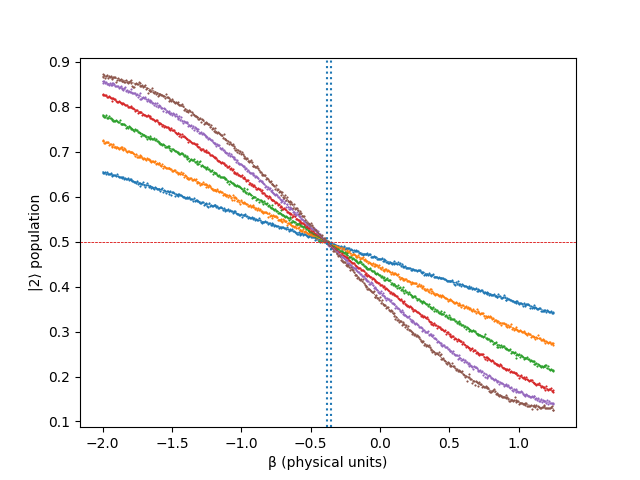

In [12]:
fig, ax = plt.subplots()
for i in range(6):
    # ax.scatter(dl.to_physical(beta_range), add_noise(y_fit[i][:, 2], i=i), s=1, color='black')
    ax.scatter(dl.to_physical(beta_range), drape_pops[i][:, 2], lw=0.5, s=1)
    ax.plot(dl.to_physical(beta_range), y_fit[i][:,2], lw=0.5)

ax.axhline(np.cos(0.0175)**2/2, color='gray', linestyle="--", lw=0.5)
ax.axhline(np.cos(0.01655)**2/2, color='red', linestyle="--", lw=0.5)
ax.axvline(dl.to_physical(beta_range[np.argmin(np.abs(dl.to_physical(beta_range) + 0.385))]),  linestyle=":")
ax.axvline(dl.to_physical(beta_range[np.argmin(np.abs(dl.to_physical(beta_range) + 0.355))]),  linestyle=":")
ax.set_xlabel('β (physical units)')
ax.set_ylabel('|2⟩ population')

In [12]:
drape_pops_new = np.zeros((11, len(beta_range), 4))
for i in range(11):
    drape_pops_new[i] = add_noise(y_fit[i], i=i)

np.savez(dl.DATA_DIR + 'simulated/drape/0.2390/drape_sim_500pts_-2.0_1.25_0.2390_k1to11_noisier.npz',
         beta_range=beta_range, drape_pops=drape_pops_new, y_fit=y_fit)

## Re-run from scratch (slow — uncomment to use)

In [15]:
beta_range = np.linspace(-0.4, -0.37, 500)  # physical units
betas_normalized = dl.to_normalized(beta_range)
amp_uncorrected = 0.23900

In [16]:
pops = dl.simulateDRAPE(
    gamma=-0.00035678567513997076,
    rep_range=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20],
    betas_normalized=betas_normalized,
    A0=amp_uncorrected,  
    lambdas=lambdas,
)

c:\Users\user\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\qutip\solver\options.py:16: FutureWarning: Dedicated options class are no longer needed, options should be passed as dict to solvers.
  warnings.warn(


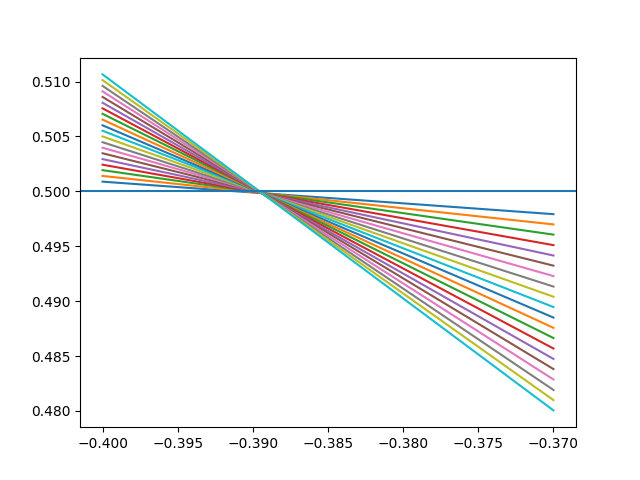

In [19]:
fig, ax = plt.subplots()

for i in range(20):
    plt.plot(beta_range, pops[i][:, 2])

ax.axhline(0.5)

In [24]:
drape_pops_new = np.zeros((pops.shape[0], len(beta_range), 4))
for i in range(20):
    drape_pops_new[i] = add_noise(pops[i], i=i)

np.savez(dl.DATA_DIR + 'simulated/drape/0.2390/drape_sim_500pts_-0.4_-0.37_0.2390_k1to21.npz',
         beta_range=betas_normalized, drape_pops=drape_pops_new, y_fit=pops, ks=np.arange(1, 20+1, 1))

## Optimize gamma against the data (~1 hour to converge)

In [ ]:
# from scipy.optimize import minimize
# amp_uncorrected = 0.2512
# pop_data        = drape_sweep_pops[:, :, 2]
# res = minimize(
#     dl.lossDRAPE,
#     x0=[-0.0007],
#     args=(pop_data, dl.DEFAULT_REP_RANGE, beta_orig, amp_uncorrected, lambdas),
#     bounds=[(-0.005, 0)],
#     method='L-BFGS-B',
# )
# print('Optimal gamma:', res.x[0])   # known good: -0.00035678567513997076

In [11]:
check = np.load(dl.DATA_DIR + '\drape_results_fit_various_gamma.npz', allow_pickle=True)

In [13]:
check_array = check['drape_results_fit_various_gamma']

In [15]:
check_array.shape

(25, 6, 50, 3)